# 01 - Sanity Checks: Data Quality and Experiment Validity

**Goal:** confirm that the data is clean and that the three groups are comparable
*before* comparing any outcome between them.

This notebook answers four questions:

1. Is the data complete and correctly typed?
2. Are the outcome columns logically consistent?
3. Were customers split into three equal groups, as designed? (sample ratio mismatch)
4. Do the three groups look alike on everything measured before the campaign? (covariate balance)


## 0. Setup and data loading

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src.db import get_engine

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.4f}".format)

In [2]:
# Load the whole table once, then release the connection
engine = get_engine()
df = pd.read_sql("SELECT * FROM customers", engine)
engine.dispose()

# MySQL DECIMAL columns arrive as Python Decimal objects; convert them to float
df["history"] = df["history"].astype(float)
df["spend"] = df["spend"].astype(float)

print(df.shape)
df.head()

(64000, 13)


,customer_id,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,1,10,2) $100 - $200,142.4400,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0000
1,2,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,0,0,0.0000
2,3,7,2) $100 - $200,180.6500,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0000
3,4,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0000
4,5,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0000


## 1. Structure and data quality

Expected: 64,000 rows, 13 columns, no missing values, one row per customer.

In [3]:
# Column types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_id      64000 non-null  int64  
 1   recency          64000 non-null  int64  
 2   history_segment  64000 non-null  str    
 3   history          64000 non-null  float64
 4   mens             64000 non-null  int64  
 5   womens           64000 non-null  int64  
 6   zip_code         64000 non-null  str    
 7   newbie           64000 non-null  int64  
 8   channel          64000 non-null  str    
 9   segment          64000 non-null  str    
 10  visit            64000 non-null  int64  
 11  conversion       64000 non-null  int64  
 12  spend            64000 non-null  float64
dtypes: float64(2), int64(7), str(4)
memory usage: 6.3 MB


In [4]:
# Missing values and duplicated customers
print("Missing values per column:")
print(df.isna().sum())
print()
print("Duplicated customer_id:", df["customer_id"].duplicated().sum())
print("Fully duplicated rows (ignoring customer_id):",
      df.drop(columns="customer_id").duplicated().sum())

Missing values per column:
customer_id        0
recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

Duplicated customer_id: 0
Fully duplicated rows (ignoring customer_id): 6562


> **Note:** fully duplicated rows are not necessarily errors here. The dataset has no
> real customer identifier and only a few coarse attributes, so two different
> customers can share exactly the same values.

In [5]:
# Every category and how often it appears. Look for typos or unexpected labels.
categorical_cols = ["history_segment", "zip_code", "channel", "segment"]
for col in categorical_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts().sort_index())
    print()

--- history_segment ---
history_segment
1) $0 - $100        22970
2) $100 - $200      14254
3) $200 - $350      12289
4) $350 - $500       6409
5) $500 - $750       4911
6) $750 - $1,000     1859
7) $1,000 +          1308
Name: count, dtype: int64

--- zip_code ---
zip_code
Rural         9563
Surburban    28776
Urban        25661
Name: count, dtype: int64

--- channel ---
channel
Multichannel     7762
Phone           28021
Web             28217
Name: count, dtype: int64

--- segment ---
segment
Mens E-Mail      21307
No E-Mail        21306
Womens E-Mail    21387
Name: count, dtype: int64



In [6]:
# Ranges of numeric columns. Binary columns must contain only 0 and 1.
numeric_cols = ["recency", "history", "mens", "womens", "newbie",
                "visit", "conversion", "spend"]
display(df[numeric_cols].describe().T)

binary_cols = ["mens", "womens", "newbie", "visit", "conversion"]
for col in binary_cols:
    values = sorted(int(v) for v in df[col].unique())
    print(f"{col}: {values}")

,count,mean,std,min,25%,50%,75%,max
recency,"64,000.0000",5.7637,3.5076,1.0000,2.0000,6.0000,9.0000,12.0000
history,"64,000.0000",242.0857,256.1586,29.9900,64.6600,158.1100,325.6575,"3,345.9300"
mens,"64,000.0000",0.5510,0.4974,0.0000,0.0000,1.0000,1.0000,1.0000
womens,"64,000.0000",0.5497,0.4975,0.0000,0.0000,1.0000,1.0000,1.0000
newbie,"64,000.0000",0.5022,0.5000,0.0000,0.0000,1.0000,1.0000,1.0000
visit,"64,000.0000",0.1468,0.3539,0.0000,0.0000,0.0000,0.0000,1.0000
conversion,"64,000.0000",0.0090,0.0946,0.0000,0.0000,0.0000,0.0000,1.0000
spend,"64,000.0000",1.0509,15.0364,0.0000,0.0000,0.0000,0.0000,499.0000


mens: [0, 1]
womens: [0, 1]
newbie: [0, 1]
visit: [0, 1]
conversion: [0, 1]


**Your notes (fill in after running):**

- Missing values: None in any of the 13 columns
- Duplicates: `customer_id` has no duplicates. 6562 rows are identical to another row when `customer_id` is ignored.
- Unexpected category labels or typos: `zip_code` contains the label `Surburban`, a misspelling of
  "Suburban". It is used consistently, so it is left unchanged.
- Numeric ranges that look wrong: None

## 2. Logical consistency

Three rules that must hold if the data was recorded correctly:

1. A customer who purchased is expected to have visited the website
   (`conversion = 1` implies `visit = 1`). This is an assumption to verify, not a
   given: the source does not state through which channel purchases were recorded.
2. Money is spent only by customers who purchased (`spend > 0` exactly when `conversion = 1`).
3. `history_segment` must agree with `history` (each segment covers its own dollar range).

These checks use all customers pooled together, not group by group.

In [7]:
rule_1 = ((df["conversion"] == 1) & (df["visit"] == 0)).sum()
rule_2a = ((df["spend"] > 0) & (df["conversion"] == 0)).sum()
rule_2b = ((df["spend"] == 0) & (df["conversion"] == 1)).sum()

print("Purchased without visiting:      ", rule_1)
print("Spent money without purchasing:  ", rule_2a)
print("Purchased but spent nothing:     ", rule_2b)

Purchased without visiting:       0
Spent money without purchasing:   0
Purchased but spent nothing:      0


In [8]:
# Each history_segment should cover a separate, non-overlapping range of `history`
display(
    df.groupby("history_segment")["history"]
      .agg(["count", "min", "max"])
      .sort_values("min")
)

,count,min,max
history_segment,,,
1) $0 - $100,22970,29.9900,99.9900
2) $100 - $200,14254,100.0000,199.9800
3) $200 - $350,12289,200.0000,349.9600
4) $350 - $500,6409,350.0100,499.9500
5) $500 - $750,4911,500.0000,749.7900
"6) $750 - $1,000",1859,750.0100,999.7500
"7) $1,000 +",1308,"1,000.1500","3,345.9300"


In [9]:
# Customers who bought neither men's nor women's merchandise in the past year
pd.crosstab(df["mens"], df["womens"], margins=True)

womens,0,1,All
mens,,,
0,0,28734,28734
1,28818,6448,35266
All,28818,35182,64000


**Your notes:**

- **Rule 1 (purchase implies visit):** holds for every customer (0 violations).
  Recorded purchases therefore appear to be website purchases. Purchases through
  other channels, such as phone, may not be captured, which is noted as a limitation.
- **Rule 2 (spend matches conversion):** holds for every customer (0 violations).
  Money is only spent by customers who purchased.
- **Rule 3 (history segments):** each segment's minimum and maximum `history`
  fall inside the range in its label, the seven ranges do not overlap, and the
  segment counts add up to 64,000.
- **Anything surprising in the mens/womens table:** no customer has `mens = 0` and `womens = 0`, which is
  consistent with a dataset of customers who purchased in the past twelve months.
  Customers split into three types: men's merchandise only (28,818, 45.0%), women's
  merchandise only (28,734, 44.9%), and both (6,448, 10.1%).

## 3. Sample ratio mismatch (SRM)

The experiment was designed as an equal three-way split. If the actual group sizes
differ from one third each by more than chance allows, something may have gone wrong
in the assignment or in data collection, and every later comparison becomes suspect.

**Test:** chi-square goodness of fit.

- H0: customers were assigned to the three groups with equal probability (1/3 each).
- Statistic: $\chi^2 = \sum \frac{(O_i - E_i)^2}{E_i}$ with $k - 1 = 2$ degrees of freedom.
- Threshold from `analysis_plan.md`: a p-value below 0.001 is a warning sign.
  The threshold is strict because with large samples, small harmless deviations
  can produce moderately small p-values.

In [10]:
observed = df["segment"].value_counts().sort_index()
expected = pd.Series(len(df) / len(observed), index=observed.index)

srm_table = pd.DataFrame({
    "observed": observed,
    "expected": expected,
    "difference": observed - expected,
    "share": observed / len(df),
})
display(srm_table)

,observed,expected,difference,share
segment,,,,
Mens E-Mail,21307,"21,333.3333",-26.3333,0.3329
No E-Mail,21306,"21,333.3333",-27.3333,0.3329
Womens E-Mail,21387,"21,333.3333",53.6667,0.3342


In [11]:
# Manual calculation, to see where the number comes from
chi2_manual = ((observed - expected) ** 2 / expected).sum()
dof = len(observed) - 1
p_manual = stats.chi2.sf(chi2_manual, dof)
print(f"Manual: chi2 = {chi2_manual:.4f}, dof = {dof}, p-value = {p_manual:.4f}")

# Same test with SciPy
chi2_scipy, p_scipy = stats.chisquare(f_obs=observed, f_exp=expected)
print(f"SciPy:  chi2 = {chi2_scipy:.4f}, p-value = {p_scipy:.4f}")

SRM_ALPHA = 0.001
print()
print("SRM warning!" if p_scipy < SRM_ALPHA else "No evidence of sample ratio mismatch.")

Manual: chi2 = 0.2025, dof = 2, p-value = 0.9037
SciPy:  chi2 = 0.2025, p-value = 0.9037

No evidence of sample ratio mismatch.


**Your interpretation:**

- chi-square statistic and p-value: Same result
  1. Manual: chi2 = 0.2025, dof = 2, p-value = 0.9037
  2. SciPy: chi2 = 0.2025, p-value = 0.9037
- Conclusion (is the split consistent with 1/3 each?): 
  The split is consistent with one third per group. The p-value is far
  above the 0.001 warning threshold, so there is no evidence of sample ratio mismatch.
  The largest deviation is 54 customers in the Womens E-Mail group, about 0.25% of the
  expected 21,333. Group shares are 33.29%, 33.29%, and 33.42%.

## 4. Covariate balance

Randomization should make the three groups similar on every characteristic measured
**before** the campaign. If one group had, for example, many more high-spending
customers, a difference in outcomes could come from that instead of from the e-mail.

**Metric:** standardized mean difference (SMD) between two groups A and B:

$$\text{SMD} = \frac{\bar{x}_A - \bar{x}_B}{\sqrt{(s_A^2 + s_B^2) / 2}}$$

It expresses the difference in means in units of standard deviation, so it can be
compared across variables with different scales. Unlike a p-value, it does not grow
with sample size. Threshold from `analysis_plan.md`: |SMD| > 0.1 counts as an imbalance.

In [12]:
# Pre-campaign columns only. Categorical columns become 0/1 dummy columns.
pre_numeric = ["recency", "history", "mens", "womens", "newbie"]
pre_categorical = ["zip_code", "channel", "history_segment"]

covariates = pd.concat(
    [df[pre_numeric].astype(float),
     pd.get_dummies(df[pre_categorical], dtype=float)],
    axis=1,
)
print(covariates.shape[1], "covariate columns")
covariates.head(3)

18 covariate columns


,recency,history,mens,womens,newbie,zip_code_Rural,zip_code_Surburban,zip_code_Urban,channel_Multichannel,channel_Phone,channel_Web,history_segment_1) $0 - $100,history_segment_2) $100 - $200,history_segment_3) $200 - $350,history_segment_4) $350 - $500,history_segment_5) $500 - $750,"history_segment_6) $750 - $1,000","history_segment_7) $1,000 +"
0,10.0000,142.4400,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,6.0000,329.0800,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000
2,7.0000,180.6500,0.0000,1.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000


In [13]:
# Mean of every covariate per group
group_means = covariates.groupby(df["segment"]).mean().T
display(group_means)

segment,Mens E-Mail,No E-Mail,Womens E-Mail
recency,5.7736,5.7497,5.7678
history,242.8359,240.8827,242.5366
mens,0.5509,0.5532,0.5489
womens,0.5514,0.5476,0.5501
newbie,0.5015,0.5020,0.5032
zip_code_Rural,0.1522,0.1473,0.1487
zip_code_Surburban,0.4459,0.4518,0.4512
zip_code_Urban,0.4019,0.4009,0.4001
channel_Multichannel,0.1209,0.1223,0.1206
channel_Phone,0.4337,0.4378,0.4420


In [14]:
def smd(a, b):
    """Standardized mean difference between two samples."""
    pooled_sd = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return (a.mean() - b.mean()) / pooled_sd if pooled_sd > 0 else 0.0


pairs = [
    ("Mens E-Mail", "No E-Mail"),
    ("Womens E-Mail", "No E-Mail"),
    ("Mens E-Mail", "Womens E-Mail"),
]

smd_table = pd.DataFrame({
    f"{a} vs {b}": {
        col: smd(covariates.loc[df["segment"] == a, col],
                 covariates.loc[df["segment"] == b, col])
        for col in covariates.columns
    }
    for a, b in pairs
})

SMD_THRESHOLD = 0.1
display(smd_table.style.format("{:+.4f}"))
print("Largest absolute SMD:", round(smd_table.abs().max().max(), 4))
print("Covariates above threshold:", int((smd_table.abs() > SMD_THRESHOLD).any(axis=1).sum()))

,Mens E-Mail vs No E-Mail,Womens E-Mail vs No E-Mail,Mens E-Mail vs Womens E-Mail
recency,+0.0068,+0.0052,+0.0016
history,+0.0076,+0.0065,+0.0012
mens,-0.0046,-0.0086,+0.0040
womens,+0.0076,+0.0049,+0.0026
newbie,-0.0009,+0.0026,-0.0034
zip_code_Rural,+0.0137,+0.0040,+0.0097
zip_code_Surburban,-0.0117,-0.0011,-0.0107
zip_code_Urban,+0.0020,-0.0018,+0.0037
channel_Multichannel,-0.0042,-0.0053,+0.0011
channel_Phone,-0.0083,+0.0086,-0.0169


Largest absolute SMD: 0.0169
Covariates above threshold: 0


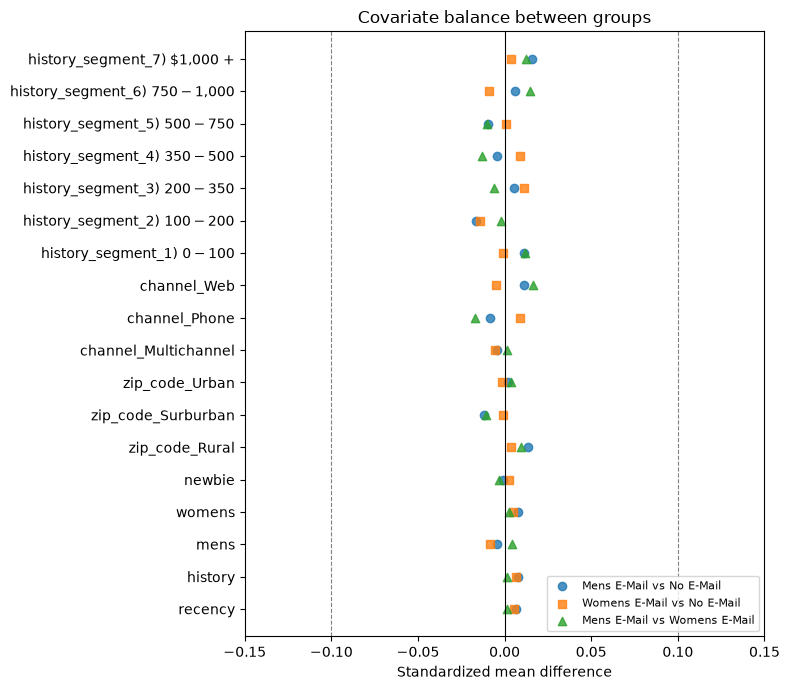

In [15]:
# Balance plot ("love plot"): every point should sit well inside the dashed lines
fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(smd_table))
for label, marker in zip(smd_table.columns, ["o", "s", "^"]):
    ax.scatter(smd_table[label], y, marker=marker, label=label, alpha=0.8)

ax.axvline(0, color="black", linewidth=0.8)
ax.axvline(SMD_THRESHOLD, color="grey", linestyle="--", linewidth=0.8)
ax.axvline(-SMD_THRESHOLD, color="grey", linestyle="--", linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels(smd_table.index)
ax.set_xlim(-0.15, 0.15)
ax.set_xlabel("Standardized mean difference")
ax.set_title("Covariate balance between groups")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()

figure_dir = ROOT / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "01_covariate_balance.png", dpi=150)
plt.show()

### Formal tests as a cross-check

SMD measures the *size* of an imbalance. As a second opinion, test each
pre-campaign variable for a difference across the three groups:

- categorical and binary variables: chi-square test of independence
- numeric variables: Kruskal-Wallis test (no normality assumption; `history` is skewed)

With 8 tests at alpha = 0.05, one "significant" result by pure chance would not be
alarming. Read these p-values together with the SMD values, not on their own.

In [16]:
rows = []

for col in ["mens", "womens", "newbie", "zip_code", "channel", "history_segment"]:
    table = pd.crosstab(df[col], df["segment"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    rows.append({"variable": col, "test": "chi-square", "statistic": chi2, "p_value": p})

for col in ["recency", "history"]:
    samples = [g[col].to_numpy() for _, g in df.groupby("segment")]
    stat, p = stats.kruskal(*samples)
    rows.append({"variable": col, "test": "Kruskal-Wallis", "statistic": stat, "p_value": p})

balance_tests = pd.DataFrame(rows).set_index("variable")
display(balance_tests)
print("Smallest p-value:", round(balance_tests["p_value"].min(), 4))

,test,statistic,p_value
variable,,,
mens,chi-square,0.7960,0.6717
womens,chi-square,0.6325,0.7289
newbie,chi-square,0.1369,0.9339
zip_code,chi-square,2.8719,0.5795
channel,chi-square,3.6324,0.4580
history_segment,chi-square,13.1533,0.3580
recency,Kruskal-Wallis,0.4611,0.7941
history,Kruskal-Wallis,0.8102,0.6669


Smallest p-value: 0.358


**Your interpretation:**

- Largest |SMD| and which covariate: 0.0169 (channel_Phone)
- Number of covariates above the 0.1 threshold: 0
- Formal tests (any p-value below 0.05? is that worrying given 8 tests?): None

## 5. Conclusion

Fill in after running the notebook, in 3 to 5 sentences:

- **Data quality:** Really good as the data is clean. No missing / inconsistent values and pretty normal in statistics value
- **Logical consistency:** All three rules hold with zero violations.
- **Sample ratio:** No evidence of sample ratio mismatch (chi2 = 0.2025, p = 0.9037).
  Group shares are 33.29%, 33.29%, and 33.42%.
- **Covariate balance:** The three groups are well balanced
- **Overall:** the randomization looks healthy, so differences in outcomes between
  groups can be attributed to the e-mails.